---correlation between features---

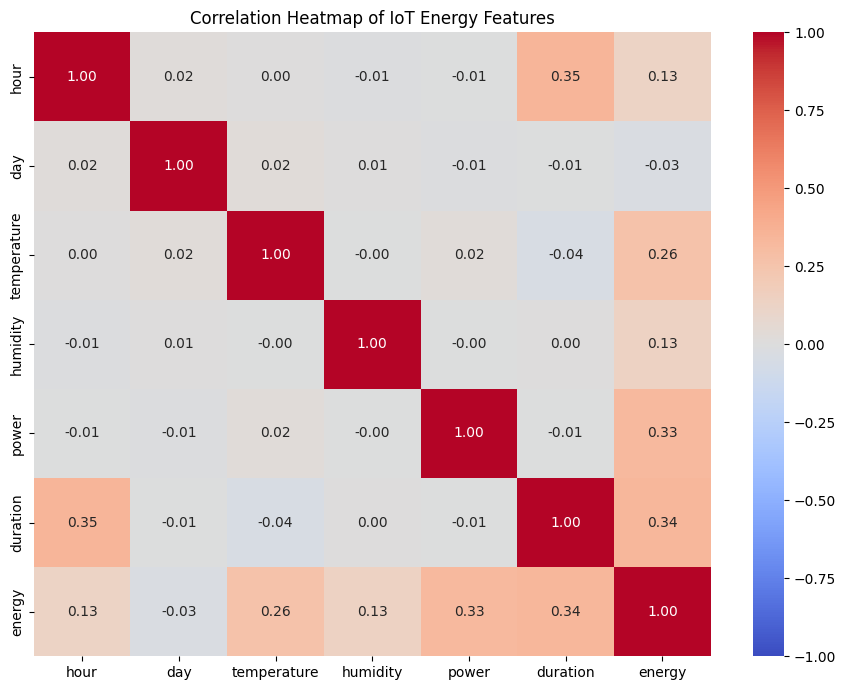

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/college_iot_energy_monitoring.csv")

numeric_cols = [
    "hour", "day", "temperature",
    "humidity", "power", "duration", "energy"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap of IoT Energy Features")
plt.tight_layout()
plt.show()


* if we observe correlation marix no multi collinearity is there in between independent features

---Outlier detection----
1) Box Plot

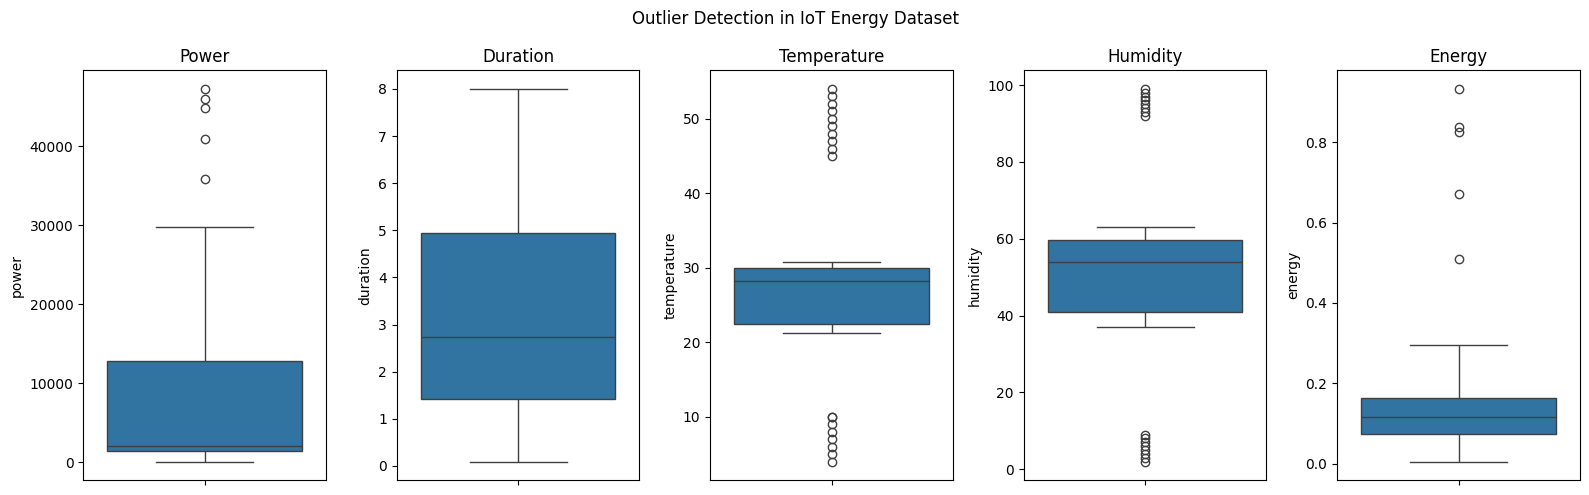

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



columns = ["power", "duration", "temperature", "humidity", "energy"]

fig, axes = plt.subplots(1, len(columns), figsize=(16, 5))

for ax, col in zip(axes, columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col.capitalize())

plt.suptitle("Outlier Detection in IoT Energy Dataset")
plt.tight_layout()
plt.show()


inquartile method to remove outliers

In [ ]:

import pandas as pd

df = pd.read_csv(
    "college_iot_energy_monitoring.csv"
)

numeric_cols = df.select_dtypes(include="number").columns

outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1


    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    # Store results
    outlier_results.append({
        "Feature": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage (%)": round(
            len(outliers) / len(df) * 100, 2
        )
    })


# Display summary
outlier_summary = pd.DataFrame(outlier_results)
print(outlier_summary.to_string(index=False))


    Feature      Q1       Q3      IQR  Lower Bound  Upper Bound  Outlier Count  Outlier Percentage (%)
       hour    5.00    18.00    13.00       -14.50        37.50              0                    0.00
        day    9.00    24.00    15.00       -13.50        46.50              0                    0.00
temperature   22.40    29.96     7.56        11.06        41.30             18                    0.90
   humidity   40.83    59.80    18.97        12.37        88.26             16                    0.80
      power 1406.11 12803.28 11397.17    -15689.64     29899.03              5                    0.25
   duration    1.41     4.94     3.53        -3.88        10.24              0                    0.00
     energy    0.07     0.16     0.09        -0.06         0.30              5                    0.25


inspecting outliers

In [ ]:


features = ["temperature", "humidity", "power", "energy"]

for col in features:
    # Calculate IQR bounds
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Select rows where this particular feature is an outlier
    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print("\n" + "=" * 70)
    print(f"{col.upper()} OUTLIER ROWS")
    print(f"Total outliers: {len(outliers)}")
    print(f"Lower bound: {lower_bound:.3f}")
    print(f"Upper bound: {upper_bound:.3f}")
    print("=" * 70)

    # Show the feature's outlier values with their complete row details
    print(outliers.to_string(index=True))



TEMPERATURE OUTLIER ROWS
Total outliers: 18
Lower bound: 11.060
Upper bound: 41.300
                                            device  hour  day  temperature  humidity         power  duration    energy
46     Mechanical Block - Workshop Electrical Load    22   23         52.0     55.95   1522.866632    7.2403  0.126499
51        Agriculture Block - Climate Control Load     2    2         47.0     37.75   2338.707908    1.1420  0.025654
335                Mechanical Block - Machine Load    14   27         48.0     58.83  15670.473292    1.0042  0.109494
365       Agriculture Block - Climate Control Load     9   18          8.0     59.30   1714.626207    4.3537  0.130425
447       Agriculture Block - Climate Control Load     7   10          5.0     43.53   1915.017467    2.1368  0.129905
515    Mechanical Block - Hydraulic Equipment Load     3   10         10.0     40.32   1179.549475    1.2557  0.059669
550       Agriculture Block - Field Equipment Load    16   14          7.0     38.

* here we can conclude one thing that a temperature and humidity are real outliers because these outliers are not influencing the energy (energy will also be high if both terms have high values but in this case its not energy still in same phase) and later power aswell we multiple devices with has some fixed power but if 5 values going out of the line means they are definetly outliers so removing them is better choice.
* On the other end, if we observe energy values those are consistently giving output based on all other features.

---Removing Outliers---

In [ ]:
features_to_remove = ["temperature", "humidity", "power"]

combined_mask = pd.Series(False, index=df.index)

for col in features_to_remove:
    combined_mask |= outlier_masks[col]

df_cleaned = df.loc[~combined_mask].copy()

print("\n--- CLEANING SUMMARY ---")
print("Original rows:", len(df))
print("Unique rows removed:", int(combined_mask.sum()))
print("Remaining rows:", len(df_cleaned))

# Step 3: Save cleaned dataset
output_file = "college_iot_energy_monitoring_cleaned.csv"
df_cleaned.to_csv(output_file, index=False)

print("\nCleaned dataset saved as:", output_file)

# Step 4: Check outlier counts after removal
print("\n--- OUTLIERS AFTER CLEANING ---")

for col in numeric_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    remaining = (
        (df_cleaned[col] < lower) |
        (df_cleaned[col] > upper)
    ).sum()

    print(f"{col}: {remaining}")



--- CLEANING SUMMARY ---
Original rows: 2000
Unique rows removed: 39
Remaining rows: 1961

Cleaned dataset saved as: college_iot_energy_monitoring_cleaned.csv

--- OUTLIERS AFTER CLEANING ---
hour: 0
day: 0
temperature: 0
humidity: 0
power: 0
duration: 0
energy: 5


dataset after removal of outliers

In [ ]:

import pandas as pd

df = pd.read_csv("college_iot_energy_monitoring_cleaned.csv")

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
print(df.describe().T)


Dataset shape: (1961, 8)

Missing values:
device         0
hour           0
day            0
temperature    0
humidity       0
power          0
duration       0
energy         0
dtype: int64

Duplicate rows: 0

Summary statistics:
              count         mean           std        min          25%  \
hour         1961.0    11.609893      7.008980   0.000000     5.000000   
day          1961.0    16.501785      8.853117   1.000000     9.000000   
temperature  1961.0    26.663636      3.530336  21.200000    22.420000   
humidity     1961.0    51.174396      8.934146  37.000000    40.840000   
power        1961.0  8356.532272  11252.632743  97.097051  1405.044659   
duration     1961.0     3.239365      2.234094   0.093000     1.417100   
energy       1961.0     0.122011      0.073935   0.005000     0.074391   

                     50%           75%           max  
hour           12.000000     18.000000     23.000000  
day            17.000000     24.000000     31.000000  
temperature

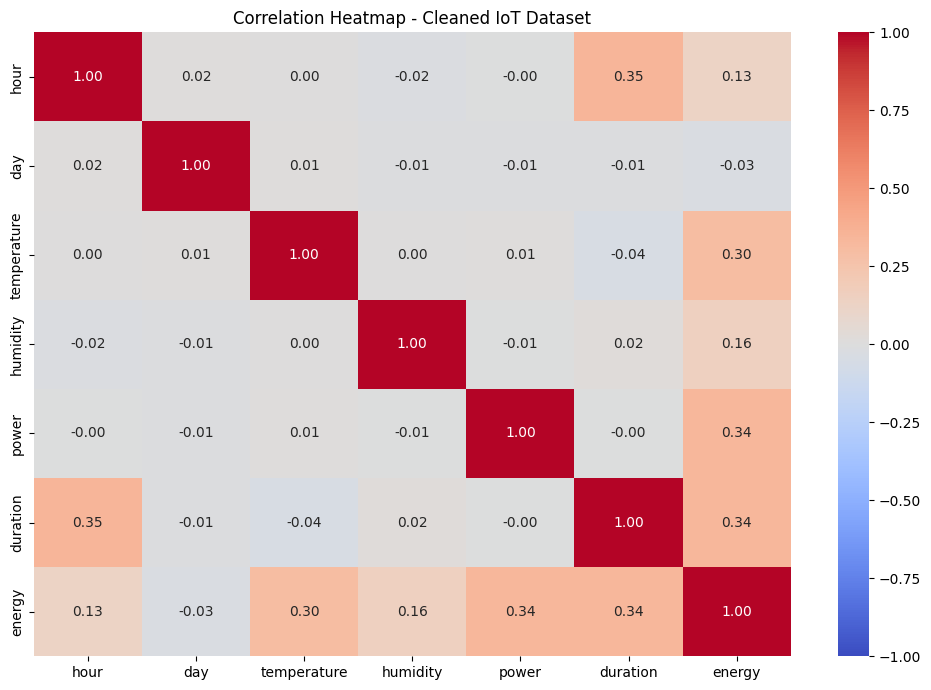


Correlation with Energy:
duration       0.338570
power          0.336629
temperature    0.304421
humidity       0.155205
hour           0.126330
day           -0.029555
Name: energy, dtype: float64


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("college_iot_energy_monitoring_cleaned.csv")

# Select numerical features
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Cleaned IoT Dataset")
plt.tight_layout()
plt.show()

# Show correlation with target
print("\nCorrelation with Energy:")
print(
    corr_matrix["energy"]
    .drop("energy")
    .sort_values(ascending=False)
)
